**Sections:**
1. Imports & Config
2. Metadata & Image Verification
3. Splits (lesion-level for 7-class, random for binary)
4. Data Pipelines
5. Class Weights
6. Model Training — 7-class DenseNet121
7. Model Training — Binary DenseNet201
8. Save Models
9. Evaluation — 7-class
10. Evaluation — Binary
11. Confusion Matrix (both)
12. ROC Curves (both)
13. Malignant vs Benign analysis
14. Grad-CAM / SHAP explainability
15. Error Analysis
16. Confidence Analysis
17. Final Results Table

**MOUNT**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, shutil, time

SRC = "/content/drive/MyDrive/skin_cancer_project/ISIC-images"
DST = "/content/ISIC-images"

n_src = sum(1 for _, _, fs in os.walk(SRC)
            for f in fs if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(f"Drive source images: {n_src}")

if os.path.exists(DST):
    print("Removing incomplete local copy...")
    shutil.rmtree(DST)
    print("Removed.")

print("Copying from Drive (2–5 minutes)...")
t0 = time.time()
shutil.copytree(SRC, DST)
print(f"Copied in {time.time()-t0:.1f}s")

n_dst = sum(1 for _, _, fs in os.walk(DST)
            for f in fs if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(f"Local SSD images now: {n_dst}")
print(f"Match: {n_src == n_dst}")

Drive source images: 11720
Copying from Drive (2–5 minutes)...
Copied in 229.3s
Local SSD images now: 11720
Match: True


**1. IMPORTS & CONFIG**

In [3]:
import os, glob, random, json, time, shutil, warnings
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, auc as sk_auc)
from sklearn.preprocessing import label_binarize
import tensorflow as tf
from tensorflow.keras import layers, Model, applications, optimizers, callbacks

warnings.filterwarnings("ignore")

DATASET_DIR   = "/content/ISIC-images"
METADATA_PATH = "/content/drive/MyDrive/skin_cancer_project/metadata.csv"
OUTPUT_DIR    = "/content/drive/MyDrive/skin_cancer_project/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE      = 224
BATCH_SIZE    = 64
RANDOM_SEED   = 42
AUTOTUNE      = tf.data.AUTOTUNE

CLASS_NAMES_7  = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX_7 = {c: i for i, c in enumerate(CLASS_NAMES_7)}
IDX_TO_CLASS_7 = {i: c for c, i in CLASS_TO_IDX_7.items()}
NUM_CLASSES_7  = 7
MALIGNANT_CLASSES = {"mel", "bcc", "akiec"}

CLASS_NAMES_2  = ["Benign", "Malignant"]
CLASS_TO_IDX_2 = {"Benign": 0, "Malignant": 1}
NUM_CLASSES_2  = 2

DIAG3_TO_CLASS = {
    "Nevus":                         "nv",
    "Pigmented benign keratosis":    "bkl",
    "Melanoma, NOS":                 "mel",
    "Basal cell carcinoma":          "bcc",
    "Squamous cell carcinoma, NOS":  "akiec",
    "Solar or actinic keratosis":    "akiec",
    "Dermatofibroma":                "df",
}
DIAG2_FALLBACK = {
    "Benign soft tissue proliferations - Vascular": "vasc",
}
KEEP_BINARY = {"nv": "Benign", "bkl": "Benign",
               "mel": "Malignant", "bcc": "Malignant"}

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

**2. METADATA & IMAGE VERIFICATION**

In [5]:
def derive_class(row):
    d3 = row.get("diagnosis_3")
    if isinstance(d3, str) and d3 in DIAG3_TO_CLASS:
        return DIAG3_TO_CLASS[d3]
    d2 = row.get("diagnosis_2")
    if isinstance(d2, str) and d2 in DIAG2_FALLBACK:
        return DIAG2_FALLBACK[d2]
    return None


print("Loading metadata...")
df = pd.read_csv(METADATA_PATH)
df["class_label"] = df.apply(derive_class, axis=1)
df = df[df["class_label"].notna()].reset_index(drop=True)

print("Indexing images...")
all_paths = []
for ext in ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"):
    all_paths.extend(glob.glob(os.path.join(DATASET_DIR, "**", ext),
                               recursive=True))
image_index = {}
for p in all_paths:
    stem = os.path.splitext(os.path.basename(p))[0]
    image_index.setdefault(stem, []).append(p)


def find_image_path(isic_id):
    s = str(isic_id).strip()
    if s in image_index:
        return image_index[s][0]
    s2 = os.path.splitext(s)[0]
    return image_index.get(s2, [None])[0]


df["image_path"] = df["isic_id"].astype(str).apply(find_image_path)
df = df[df["image_path"].notna()].reset_index(drop=True)
print(f"Total usable rows: {len(df)}")

Loading metadata...
Indexing images...
Total usable rows: 11720


**3. Splits (lesion-level for 7-class, random for binary)**

In [6]:
VAL_RATIO  = 0.15
TEST_RATIO = 0.15

gss1 = GroupShuffleSplit(n_splits=1, test_size=(VAL_RATIO + TEST_RATIO),
                         random_state=RANDOM_SEED)
tr_idx, tmp_idx = next(gss1.split(df, groups=df["lesion_id"]))
df_train_7 = df.iloc[tr_idx].reset_index(drop=True)
df_temp_7  = df.iloc[tmp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1,
                         test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
                         random_state=RANDOM_SEED)
val_idx, test_idx = next(gss2.split(df_temp_7, groups=df_temp_7["lesion_id"]))
df_val_7  = df_temp_7.iloc[val_idx].reset_index(drop=True)
df_test_7 = df_temp_7.iloc[test_idx].reset_index(drop=True)

assert not (set(df_train_7["lesion_id"]) & set(df_val_7["lesion_id"]))
assert not (set(df_train_7["lesion_id"]) & set(df_test_7["lesion_id"]))
assert not (set(df_val_7["lesion_id"]) & set(df_test_7["lesion_id"]))

print(f"[7-class] train={len(df_train_7)}  val={len(df_val_7)}  test={len(df_test_7)}")

# --- Binary: random image-level split (Karboua) ---
df_bin = df[df["class_label"].isin(KEEP_BINARY)].copy()
df_bin["binary_label"] = df_bin["class_label"].map(KEEP_BINARY)

df_tr_2, df_tmp_2 = train_test_split(
    df_bin, test_size=0.30, stratify=df_bin["binary_label"],
    random_state=RANDOM_SEED)
df_va_2, df_te_2 = train_test_split(
    df_tmp_2, test_size=0.50, stratify=df_tmp_2["binary_label"],
    random_state=RANDOM_SEED)
df_tr_2  = df_tr_2.reset_index(drop=True)
df_va_2  = df_va_2.reset_index(drop=True)
df_te_2  = df_te_2.reset_index(drop=True)

print(f"[Binary]  train={len(df_tr_2)}  val={len(df_va_2)}  test={len(df_te_2)}")


[7-class] train=8190  val=1764  test=1766
[Binary]  train=7701  val=1650  test=1651


**4. Data Pipelines**

In [7]:
def _decode_densenet(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.densenet.preprocess_input(img)
    return img, label


def augment_densenet(img, label):
    img = tf.image.random_flip_left_right(img, seed=RANDOM_SEED)
    img = tf.image.random_flip_up_down(img, seed=RANDOM_SEED)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32, seed=RANDOM_SEED)
    img = tf.image.rot90(img, k=k)
    crop = int(IMG_SIZE * 0.90)
    img = tf.image.random_crop(img, [crop, crop, 3], seed=RANDOM_SEED)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.image.random_brightness(img, 0.10, seed=RANDOM_SEED)
    img = tf.image.random_contrast(img, 0.90, 1.10, seed=RANDOM_SEED)
    img = tf.clip_by_value(img, -1.0, 1.0)
    return img, label


def make_ds_7(dataframe, shuffle=False, augment_fn=None):
    paths  = dataframe["image_path"].astype(str).values
    labels = dataframe["class_label"].map(CLASS_TO_IDX_7).astype(np.int32).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(min(len(paths), 2000), seed=RANDOM_SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(_decode_densenet, num_parallel_calls=AUTOTUNE, deterministic=False)
    if augment_fn:
        ds = ds.map(augment_fn, num_parallel_calls=AUTOTUNE, deterministic=False)
    ds = ds.map(lambda im, lb: (im, tf.one_hot(lb, NUM_CLASSES_7)),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


def make_ds_2(dataframe, shuffle=False, augment_fn=None):
    paths  = dataframe["image_path"].astype(str).values
    labels = dataframe["binary_label"].map(CLASS_TO_IDX_2).astype(np.int32).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(min(len(paths), 4000), seed=RANDOM_SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(_decode_densenet, num_parallel_calls=AUTOTUNE, deterministic=False)
    if augment_fn:
        ds = ds.map(augment_fn, num_parallel_calls=AUTOTUNE, deterministic=False)
    ds = ds.map(lambda im, lb: (im, tf.one_hot(lb, NUM_CLASSES_2)),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds_7 = make_ds_7(df_train_7, shuffle=True, augment_fn=augment_densenet)
val_ds_7   = make_ds_7(df_val_7)
test_ds_7  = make_ds_7(df_test_7)

train_ds_2 = make_ds_2(df_tr_2, shuffle=True, augment_fn=augment_densenet)
val_ds_2   = make_ds_2(df_va_2)
test_ds_2  = make_ds_2(df_te_2)

**5. Class Weights**

In [8]:
y_tr_int = df_train_7["class_label"].map(CLASS_TO_IDX_7).values
present  = np.unique(y_tr_int)
w = compute_class_weight("balanced", classes=present, y=y_tr_int)
raw = np.array([w[list(present).index(i)] if i in present else 1.0
                for i in range(NUM_CLASSES_7)])
med = np.median(raw)
capped = np.clip(raw, med / 5.0, med * 2.0)
capped = capped / capped.mean()
class_weight_7 = {i: float(capped[i]) for i in range(NUM_CLASSES_7)}

print("Class weights (7-class):")
for i in range(NUM_CLASSES_7):
    print(f"  {IDX_TO_CLASS_7[i]:>6}: {class_weight_7[i]:.3f}")


Class weights (7-class):
   akiec: 1.469
     bcc: 0.901
     bkl: 0.430
      df: 1.801
     mel: 0.417
      nv: 0.180
    vasc: 1.801


**6. Model Training — 7-class DenseNet121**

In [13]:
def build_densenet121_7class():
    base = applications.DenseNet121(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        name="densenet121_base",
    )
    base.trainable = False

    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.4, name="drop1")(x)
    x = layers.Dense(128, activation="relu", name="fc2")(x)
    x = layers.Dropout(0.3, name="drop2")(x)
    out = layers.Dense(NUM_CLASSES_7, activation="softmax",
                       dtype="float32", name="predictions")(x)
    return Model(inp, out, name="DenseNet121_7class"), base


model_7, base_7 = build_densenet121_7class()
model_7.compile(
    optimizer=optimizers.Adam(learning_rate=5e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=["accuracy"],
)

ckpt_7 = os.path.join(OUTPUT_DIR, "best_densenet121_7class.keras")

print("\nTraining DenseNet121 7-class...")
hist_7 = model_7.fit(
    train_ds_7, validation_data=val_ds_7,
    epochs=15, class_weight=class_weight_7,
    callbacks=[
        callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                    patience=3, min_lr=1e-7, verbose=1),
        callbacks.ModelCheckpoint(ckpt_7, monitor="val_loss",
                                  save_best_only=True, verbose=1),
        callbacks.CSVLogger(os.path.join(OUTPUT_DIR,
                                         "history_densenet121_7class.csv")),
    ],
    verbose=1,
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Training DenseNet121 7-class...
Epoch 1/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.4982 - loss: 0.6551
Epoch 1: val_loss improved from None to 0.96277, saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet121_7class.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet121_7class.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 105s 613ms/step - accuracy: 0.5469 - loss: 0.5985 - val_accuracy: 0.6899 - val_loss: 0.9628 - learning_rate: 5.0000e-04
Epoch 2/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.6406 - loss: 0.4752
Epoch 2: val_loss improved from 0.96277 to 0.83418, saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet121_7class.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet121_7class.keras
128/128 ━━━━━━━━━━━━━━━━━━━━ 33s 258ms/step - accuracy: 0.6297 -

**7. Model Training — Binary DenseNet201**

In [10]:
IMG_SIZE = 224
OUTPUT_DIR = "/content/drive/MyDrive/skin_cancer_project/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
ckpt_2 = os.path.join(OUTPUT_DIR, "best_densenet201_binary.keras")

def build_fast_densenet201():
    base = applications.DenseNet201(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        name="densenet201_base",
    )
    base.trainable = False
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu", name="fc1")(x)
    x = layers.Dense(128, activation="relu", name="fc2")(x)
    out = layers.Dense(2, activation="softmax", dtype="float32", name="predictions")(x)
    return Model(inp, out, name="DenseNet201_Binary"), base

model_2, base_2 = build_fast_densenet201()

model_2.compile(
    optimizer=optimizers.Adamax(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=["accuracy"],
)

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint(ckpt_2, monitor="val_loss", save_best_only=True, verbose=1),
]

hist_1 = model_2.fit(train_ds_2, validation_data=val_ds_2, epochs=3, callbacks=cbs, verbose=1)

base_2.trainable = True
for layer in base_2.layers[:-30]:
    layer.trainable = False

model_2.compile(
    optimizer=optimizers.Adamax(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=["accuracy"],
)

hist_2 = model_2.fit(train_ds_2, validation_data=val_ds_2, epochs=7, callbacks=cbs, verbose=1)

Epoch 1/3
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.8061 - loss: 0.3915
Epoch 1: val_loss improved from None to 0.35224, saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet201_binary.keras

Epoch 1: finished saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet201_binary.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 154s 928ms/step - accuracy: 0.8368 - loss: 0.3446 - val_accuracy: 0.8448 - val_loss: 0.3522 - learning_rate: 0.0010
Epoch 2/3
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.8769 - loss: 0.2805
Epoch 2: val_loss improved from 0.35224 to 0.33510, saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet201_binary.keras

Epoch 2: finished saving model to /content/drive/MyDrive/skin_cancer_project/outputs/best_densenet201_binary.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 43s 350ms/step - accuracy: 0.8734 - loss: 0.2800 - val_accuracy: 0.8515 - val_loss: 0.3351 - learning_rate: 0.0010
Epoch 3/3


**8. Save Models**

In [14]:
keras_7 = os.path.join(OUTPUT_DIR, "densenet121_7class.keras")
keras_2 = os.path.join(OUTPUT_DIR, "densenet201_binary.keras")

print("\nSaving models...")
model_7.save(keras_7)
model_2.save(keras_2)
print(f"Saved: {keras_7}")
print(f"Saved: {keras_2}")

def convert_to_tflite(keras_path, tflite_path):
    m = tf.keras.models.load_model(keras_path, compile=False)
    conv = tf.lite.TFLiteConverter.from_keras_model(m)
    conv.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS,
        tf.lite.OpsSet.SELECT_TF_OPS,
    ]
    blob = conv.convert()
    with open(tflite_path, "wb") as f:
        f.write(blob)
    print(f"TFLite: {tflite_path} ({len(blob)/1024/1024:.2f} MB)")

try:
    convert_to_tflite(keras_7, os.path.join(OUTPUT_DIR, "densenet121_7class.tflite"))
    convert_to_tflite(keras_2, os.path.join(OUTPUT_DIR, "densenet201_binary.tflite"))
except Exception as e:
    print("TFLite conversion failed:", e)


Saving models...
Saved: /content/drive/MyDrive/skin_cancer_project/outputs/densenet121_7class.keras
Saved: /content/drive/MyDrive/skin_cancer_project/outputs/densenet201_binary.keras
Saved artifact at '/tmp/tmpvod7i2w1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image_input')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  139339109084112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002002512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002000784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002002320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332001997520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002001552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002001744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332002000016: TensorSpec(shape=(), dty

**9. Evaluation — 7-class**

In [15]:
def predict_all(model, ds):
    y_true, y_proba = [], []
    for imgs, labels in ds:
        y_proba.append(model.predict(imgs, verbose=0))
        y_true.append(labels.numpy())
    return np.concatenate(y_true), np.concatenate(y_proba)


y_true_7, y_proba_7 = predict_all(model_7, test_ds_7)
y_true_int_7 = np.argmax(y_true_7, 1)
y_pred_int_7 = np.argmax(y_proba_7, 1)

print("\n" + "=" * 70)
print("EVALUATION — DenseNet121 (7-class)")
print("=" * 70)
print(f"Accuracy          : {accuracy_score(y_true_int_7, y_pred_int_7):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_true_int_7, y_pred_int_7):.4f}")
print(f"Macro F1          : {f1_score(y_true_int_7, y_pred_int_7, average='macro', zero_division=0):.4f}")
print(f"Weighted F1       : {f1_score(y_true_int_7, y_pred_int_7, average='weighted', zero_division=0):.4f}")
print(f"Macro ROC-AUC     : {roc_auc_score(y_true_7, y_proba_7, average='macro', multi_class='ovr'):.4f}")
print()
print(classification_report(y_true_int_7, y_pred_int_7,
                            target_names=CLASS_NAMES_7, digits=4,
                            zero_division=0))


EVALUATION — DenseNet121 (7-class)
Accuracy          : 0.7220
Balanced Accuracy : 0.4185
Macro F1          : 0.4444
Weighted F1       : 0.7210
Macro ROC-AUC     : 0.8988

              precision    recall  f1-score   support

       akiec     0.3659    0.3261    0.3448        46
         bcc     0.4857    0.3469    0.4048        98
         bkl     0.4679    0.4636    0.4658       220
          df     0.2222    0.1905    0.2051        21
         mel     0.3426    0.4405    0.3854       168
          nv     0.8693    0.8759    0.8726      1185
        vasc     0.8889    0.2857    0.4324        28

    accuracy                         0.7220      1766
   macro avg     0.5204    0.4185    0.4444      1766
weighted avg     0.7274    0.7220    0.7210      1766



**10. Evaluation — Binary**

In [16]:
y_true_2, y_proba_2 = predict_all(model_2, test_ds_2)
y_true_int_2 = np.argmax(y_true_2, 1)
y_pred_int_2 = np.argmax(y_proba_2, 1)

print("\n" + "=" * 70)
print("EVALUATION — DenseNet201 (Binary)")
print("=" * 70)
print(f"Accuracy          : {accuracy_score(y_true_int_2, y_pred_int_2):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_true_int_2, y_pred_int_2):.4f}")
print(f"Macro Precision   : {precision_score(y_true_int_2, y_pred_int_2, average='macro', zero_division=0):.4f}")
print(f"Macro Recall      : {recall_score(y_true_int_2, y_pred_int_2, average='macro', zero_division=0):.4f}")
print(f"Macro F1          : {f1_score(y_true_int_2, y_pred_int_2, average='macro', zero_division=0):.4f}")
print(f"ROC-AUC           : {roc_auc_score(y_true_2, y_proba_2, average='macro', multi_class='ovr'):.4f}")
print()
print(classification_report(y_true_int_2, y_pred_int_2,
                            target_names=CLASS_NAMES_2, digits=4))




EVALUATION — DenseNet201 (Binary)
Accuracy          : 0.8589
Balanced Accuracy : 0.6923
Macro Precision   : 0.7654
Macro Recall      : 0.6923
Macro F1          : 0.7184
ROC-AUC           : 0.8789

              precision    recall  f1-score   support

      Benign     0.8880    0.9486    0.9173      1362
   Malignant     0.6429    0.4360    0.5196       289

    accuracy                         0.8589      1651
   macro avg     0.7654    0.6923    0.7184      1651
weighted avg     0.8451    0.8589    0.8477      1651



**11. Confusion Matrix (both)**

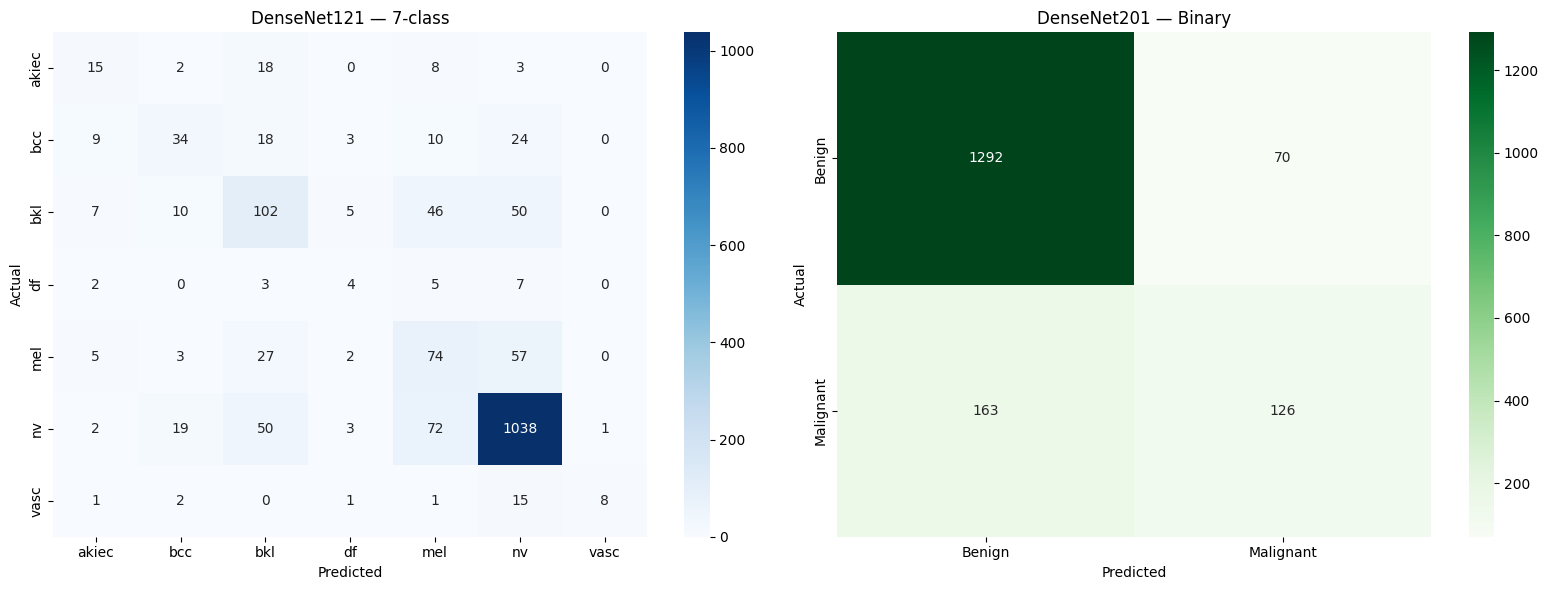

In [17]:
cm_7 = confusion_matrix(y_true_int_7, y_pred_int_7)
cm_2 = confusion_matrix(y_true_int_2, y_pred_int_2)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm_7, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES_7, yticklabels=CLASS_NAMES_7,
            ax=axes[0])
axes[0].set_title("DenseNet121 — 7-class")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_2, annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2,
            ax=axes[1])
axes[1].set_title("DenseNet201 — Binary")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices.png"), dpi=150)
plt.show()

**12. ROC Curves (both)**

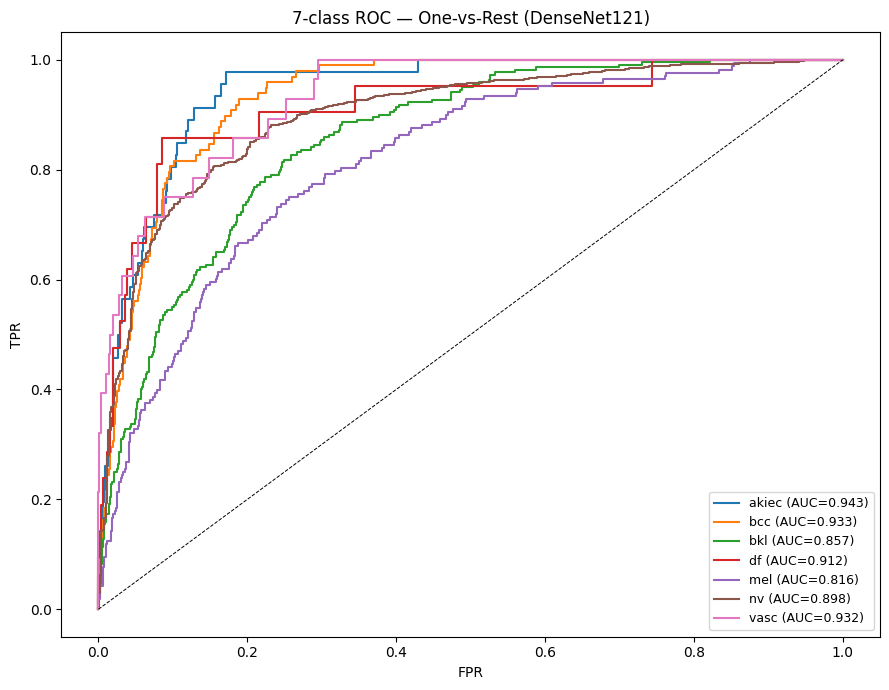

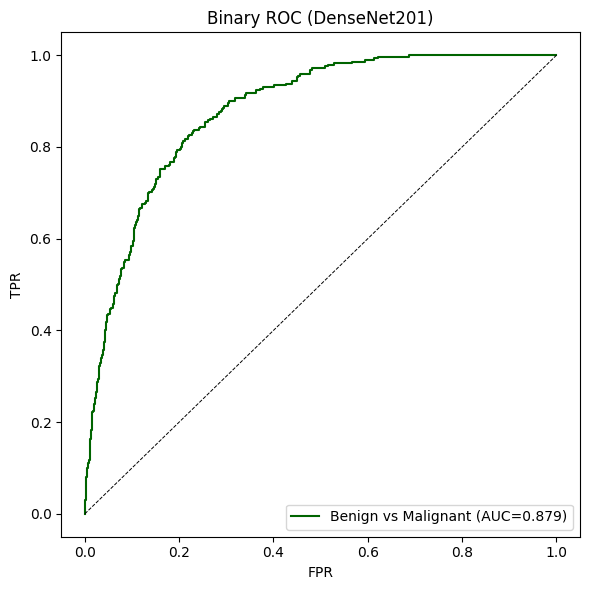

In [18]:
# 7-class ROC
y_bin_7 = label_binarize(y_true_int_7, classes=list(range(NUM_CLASSES_7)))
plt.figure(figsize=(9, 7))
for i, cls in enumerate(CLASS_NAMES_7):
    fpr, tpr, _ = roc_curve(y_bin_7[:, i], y_proba_7[:, i])
    plt.plot(fpr, tpr, label=f"{cls} (AUC={sk_auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.7)
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("7-class ROC — One-vs-Rest (DenseNet121)")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_7class.png"), dpi=150)
plt.show()

# Binary ROC
fpr_2, tpr_2, _ = roc_curve(y_true_int_2, y_proba_2[:, 1])
auc_2 = sk_auc(fpr_2, tpr_2)
plt.figure(figsize=(6, 6))
plt.plot(fpr_2, tpr_2, label=f"Benign vs Malignant (AUC={auc_2:.3f})",
         color="darkgreen")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.7)
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("Binary ROC (DenseNet201)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_binary.png"), dpi=150)
plt.show()

**13. Malignant vs Benign analysis**


MALIGNANT vs BENIGN (derived from 7-class DenseNet121)
Sensitivity (malignant recall) : 0.4712
Specificity (benign recall)    : 0.9182
Precision                      : 0.5526
F1                             : 0.5087
Accuracy                       : 0.8392
ROC-AUC                        : 0.8413
TN=1335  FP=119  FN=165  TP=147


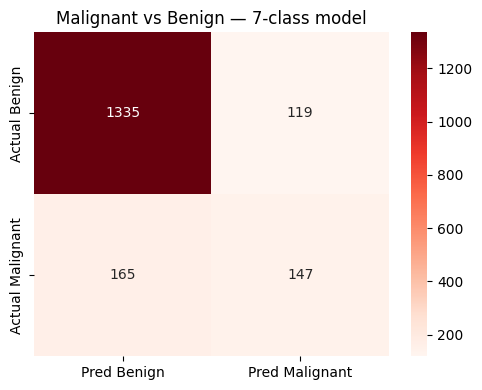

In [19]:
mal_idx = [CLASS_TO_IDX_7[c] for c in MALIGNANT_CLASSES]
mal_prob = y_proba_7[:, mal_idx].sum(axis=1)
y_true_bin = np.isin(y_true_int_7, mal_idx).astype(int)
y_pred_bin = (mal_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
sens = tp / (tp + fn) if (tp + fn) else 0.0
spec = tn / (tn + fp) if (tn + fp) else 0.0

print("\n" + "=" * 70)
print("MALIGNANT vs BENIGN (derived from 7-class DenseNet121)")
print("=" * 70)
print(f"Sensitivity (malignant recall) : {sens:.4f}")
print(f"Specificity (benign recall)    : {spec:.4f}")
print(f"Precision                      : {precision_score(y_true_bin, y_pred_bin, zero_division=0):.4f}")
print(f"F1                             : {f1_score(y_true_bin, y_pred_bin, zero_division=0):.4f}")
print(f"Accuracy                       : {accuracy_score(y_true_bin, y_pred_bin):.4f}")
print(f"ROC-AUC                        : {roc_auc_score(y_true_bin, mal_prob):.4f}")
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

plt.figure(figsize=(5, 4))
sns.heatmap(np.array([[tn, fp], [fn, tp]]), annot=True, fmt="d",
            cmap="Reds", xticklabels=["Pred Benign", "Pred Malignant"],
            yticklabels=["Actual Benign", "Actual Malignant"])
plt.title("Malignant vs Benign — 7-class model")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "malignant_vs_benign.png"), dpi=150)
plt.show()

**14. EXPLAINABILITY — Occlusion Sensitivity + SHAP**

In [20]:
def load_image_for_xai(path):
    raw = cv2.imread(path)
    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
    raw = cv2.resize(raw, (IMG_SIZE, IMG_SIZE))
    arr = tf.keras.applications.densenet.preprocess_input(raw.astype(np.float32))
    return raw, np.expand_dims(arr, axis=0)


def occlusion_sensitivity(model, img_array, pred_idx, patch=32, stride=16):
    base_p = model.predict(img_array, verbose=0)[0][pred_idx]
    h, w = img_array.shape[1:3]
    sal = np.zeros((h, w), dtype=np.float32)
    for y in range(0, h - patch + 1, stride):
        for x in range(0, w - patch + 1, stride):
            occl = img_array.copy()
            occl[0, y:y+patch, x:x+patch] = 0.0
            p = model.predict(occl, verbose=0)[0][pred_idx]
            sal[y:y+patch, x:x+patch] = base_p - p
    sal = np.maximum(sal, 0)
    return sal / (sal.max() + 1e-8)


df_test_7_reset = df_test_7.reset_index(drop=True)
correct_idx = np.where(y_true_int_7 == y_pred_int_7)[0]
wrong_idx   = np.where(y_true_int_7 != y_pred_int_7)[0]

mal_correct = [i for i in correct_idx if y_true_int_7[i] in mal_idx][:2]
mal_wrong   = [i for i in wrong_idx   if y_true_int_7[i] in mal_idx][:2]
ben_correct = [i for i in correct_idx if y_true_int_7[i] not in mal_idx][:2]
pick = mal_correct + mal_wrong + ben_correct

fig, axes = plt.subplots(len(pick), 3, figsize=(12, 3.5 * len(pick)))
if len(pick) == 1:
    axes = np.expand_dims(axes, 0)

print("\nGenerating occlusion sensitivity maps (may take ~20-40s each)...")
for r, idx in enumerate(pick):
    row = df_test_7_reset.iloc[idx]
    orig, arr = load_image_for_xai(row["image_path"])
    sal = occlusion_sensitivity(model_7, arr, y_pred_int_7[idx])
    ov = cv2.addWeighted(orig, 0.55,
                         cv2.applyColorMap(np.uint8(255 * cv2.resize(sal, (IMG_SIZE, IMG_SIZE))),
                                           cv2.COLORMAP_JET),
                         0.45, 0)
    ov = cv2.cvtColor(ov, cv2.COLOR_BGR2RGB)
    axes[r, 0].imshow(orig); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"True: {IDX_TO_CLASS_7[y_true_int_7[idx]]}")
    axes[r, 1].imshow(sal, cmap="jet"); axes[r, 1].axis("off")
    axes[r, 1].set_title("Occlusion sensitivity")
    axes[r, 2].imshow(ov); axes[r, 2].axis("off")
    axes[r, 2].set_title(f"Pred: {IDX_TO_CLASS_7[y_pred_int_7[idx]]}")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "occlusion_7class.png"), dpi=150)
plt.show()


# SHAP (if installed)
try:
    import shap
    bg_paths = df_train_7.sample(16, random_state=RANDOM_SEED)["image_path"].values
    bg_imgs = np.stack([load_image_for_xai(p)[1][0] for p in bg_paths])
    test_paths = df_test_7_reset.iloc[pick]["image_path"].values
    test_imgs = np.stack([load_image_for_xai(p)[1][0] for p in test_paths])

    explainer = shap.GradientExplainer(model_7, bg_imgs)
    shap_values = explainer.shap_values(test_imgs, nsamples=40)

    fig, axes = plt.subplots(len(test_imgs), 2, figsize=(9, 3 * len(test_imgs)))
    if len(test_imgs) == 1:
        axes = np.expand_dims(axes, 0)
    for i in range(len(test_imgs)):
        axes[i, 0].imshow((test_imgs[i] - test_imgs[i].min()) /
                          (test_imgs[i].max() - test_imgs[i].min() + 1e-8))
        axes[i, 0].set_title(f"True: {IDX_TO_CLASS_7[y_true_int_7[pick[i]]]}")
        axes[i, 0].axis("off")

        sv = shap_values[y_pred_int_7[pick[i]]][i]
        sv_map = np.mean(np.abs(sv), axis=-1)
        axes[i, 1].imshow(sv_map, cmap="hot")
        axes[i, 1].set_title("SHAP |attribution|")
        axes[i, 1].axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_7class.png"), dpi=150)
    plt.show()
except Exception as e:
    print("SHAP skipped:", e)

Output hidden; open in https://colab.research.google.com to view.

**15. Error Analysis**

In [21]:
print("\n" + "=" * 70)
print("ERROR ANALYSIS")
print("=" * 70)
print(f"Total misclassified: {len(wrong_idx)} / {len(y_true_int_7)} "
      f"({100*len(wrong_idx)/len(y_true_int_7):.1f}%)")

conf_wrong = y_proba_7[wrong_idx, y_pred_int_7[wrong_idx]]
order = np.argsort(-conf_wrong)[:10]
worst = wrong_idx[order]

print("\nMost confident misclassifications:")
print(f"{'actual':>8}  {'predicted':>10}  {'confidence':>10}  {'2nd best':>10}")
for idx in worst:
    second = np.argsort(-y_proba_7[idx])[1]
    print(f"{IDX_TO_CLASS_7[y_true_int_7[idx]]:>8}  "
          f"{IDX_TO_CLASS_7[y_pred_int_7[idx]]:>10}  "
          f"{y_proba_7[idx, y_pred_int_7[idx]]:>10.3f}  "
          f"{IDX_TO_CLASS_7[second]:>10}")

# Malignant → benign breakdown
from collections import Counter
mal_as_ben = [(int(y_true_int_7[i]), int(y_pred_int_7[i]))
              for i in wrong_idx
              if y_true_int_7[i] in mal_idx
              and y_pred_int_7[i] not in mal_idx]
pairs = Counter((IDX_TO_CLASS_7[t], IDX_TO_CLASS_7[p]) for t, p in mal_as_ben)
print(f"\nMalignant misclassified as Benign: {len(mal_as_ben)}")
for (t, p), n in pairs.most_common(10):
    print(f"  {t:>6} → {p:>6} : {n}")


ERROR ANALYSIS
Total misclassified: 491 / 1766 (27.8%)

Most confident misclassifications:
  actual   predicted  confidence    2nd best
    vasc          nv       0.992        vasc
    vasc          nv       0.986        vasc
     mel          nv       0.973         mel
     mel          nv       0.972         mel
     mel          nv       0.967         mel
    vasc          nv       0.966        vasc
    vasc          nv       0.959         mel
     mel          nv       0.933         mel
   akiec         bkl       0.921          nv
    vasc          nv       0.915         mel

Malignant misclassified as Benign: 152
     mel →     nv : 57
     mel →    bkl : 27
     bcc →     nv : 24
   akiec →    bkl : 18
     bcc →    bkl : 18
   akiec →     nv : 3
     bcc →     df : 3
     mel →     df : 2


**16. Confidence Analysis**

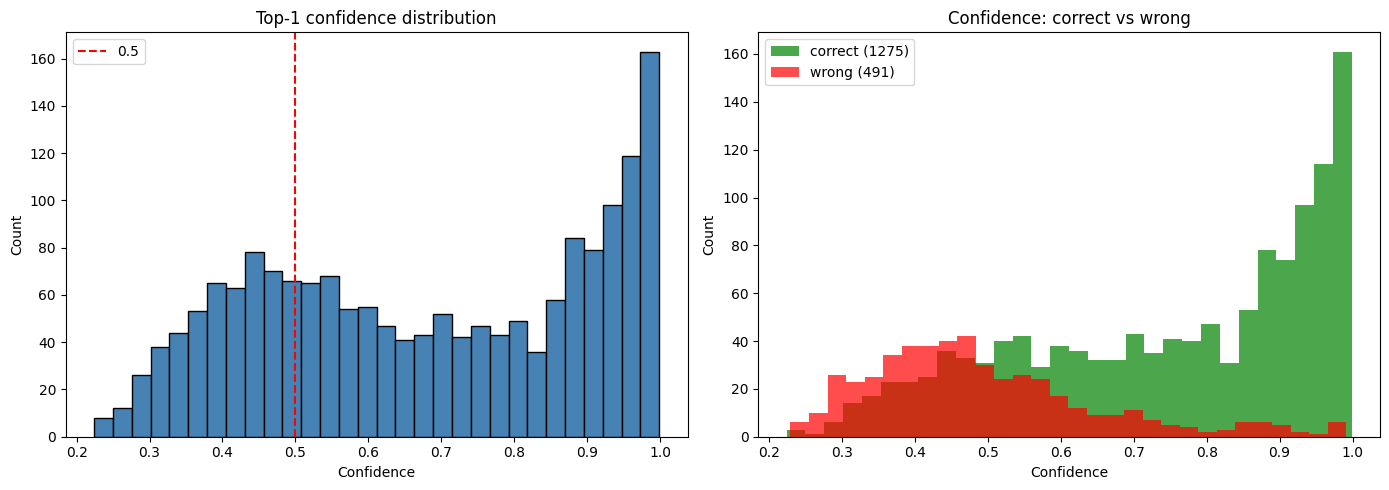


CONFIDENCE ANALYSIS
Mean confidence (correct):  0.751
Mean confidence (wrong):    0.491
Median confidence           : 0.681
Predictions with conf < 0.5 : 497


In [22]:
top_conf = y_proba_7.max(axis=1)
correct_mask = (y_true_int_7 == y_pred_int_7)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(top_conf, bins=30, color="steelblue", edgecolor="black")
axes[0].axvline(0.5, color="red", linestyle="--", label="0.5")
axes[0].set_title("Top-1 confidence distribution")
axes[0].set_xlabel("Confidence"); axes[0].set_ylabel("Count")
axes[0].legend()

axes[1].hist(top_conf[correct_mask], bins=30, alpha=0.7,
             label=f"correct ({correct_mask.sum()})", color="green")
axes[1].hist(top_conf[~correct_mask], bins=30, alpha=0.7,
             label=f"wrong ({(~correct_mask).sum()})", color="red")
axes[1].set_title("Confidence: correct vs wrong")
axes[1].set_xlabel("Confidence"); axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confidence_analysis.png"), dpi=150)
plt.show()

print("\n" + "=" * 70)
print("CONFIDENCE ANALYSIS")
print("=" * 70)
print(f"Mean confidence (correct):  {top_conf[correct_mask].mean():.3f}")
print(f"Mean confidence (wrong):    {top_conf[~correct_mask].mean():.3f}")
print(f"Median confidence           : {np.median(top_conf):.3f}")
print(f"Predictions with conf < 0.5 : {(top_conf < 0.5).sum()}")

**17. Final Results Table**

In [23]:
final = pd.DataFrame([
    ("Test Accuracy (7-class)",     f"{accuracy_score(y_true_int_7, y_pred_int_7):.4f}"),
    ("Balanced Accuracy (7-class)", f"{balanced_accuracy_score(y_true_int_7, y_pred_int_7):.4f}"),
    ("Macro F1 (7-class)",          f"{f1_score(y_true_int_7, y_pred_int_7, average='macro', zero_division=0):.4f}"),
    ("Weighted F1 (7-class)",       f"{f1_score(y_true_int_7, y_pred_int_7, average='weighted', zero_division=0):.4f}"),
    ("ROC-AUC (7-class, macro)",    f"{roc_auc_score(y_true_7, y_proba_7, average='macro', multi_class='ovr'):.4f}"),
    ("Malignant Sensitivity",       f"{sens:.4f}"),
    ("Malignant Specificity",       f"{spec:.4f}"),
    ("Binary Accuracy",             f"{accuracy_score(y_true_int_2, y_pred_int_2):.4f}"),
    ("Binary Balanced Accuracy",    f"{balanced_accuracy_score(y_true_int_2, y_pred_int_2):.4f}"),
    ("Binary Macro F1",             f"{f1_score(y_true_int_2, y_pred_int_2, average='macro', zero_division=0):.4f}"),
    ("Binary ROC-AUC",              f"{roc_auc_score(y_true_2, y_proba_2, average='macro', multi_class='ovr'):.4f}"),
], columns=["Metric", "Result"])

print("\n" + "=" * 70)
print("FINAL RESULTS")
print("=" * 70)
print(final.to_string(index=False))

final.to_csv(os.path.join(OUTPUT_DIR, "final_results.csv"), index=False)

summary = {
    "7class": {
        "model": "DenseNet121",
        "split": "lesion-level grouped",
        "accuracy": float(accuracy_score(y_true_int_7, y_pred_int_7)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true_int_7, y_pred_int_7)),
        "macro_f1": float(f1_score(y_true_int_7, y_pred_int_7, average="macro", zero_division=0)),
        "macro_roc_auc": float(roc_auc_score(y_true_7, y_proba_7, average="macro", multi_class="ovr")),
        "malignant_sensitivity": float(sens),
        "malignant_specificity": float(spec),
    },
    "binary": {
        "model": "DenseNet201",
        "split": "random image-level",
        "accuracy": float(accuracy_score(y_true_int_2, y_pred_int_2)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true_int_2, y_pred_int_2)),
        "macro_f1": float(f1_score(y_true_int_2, y_pred_int_2, average="macro", zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true_2, y_proba_2, average="macro", multi_class="ovr")),
    },
}
with open(os.path.join(OUTPUT_DIR, "final_metrics.json"), "w") as f:
    json.dump(summary, f, indent=2)

print(f"\nAll artifacts saved to {OUTPUT_DIR}")
print("Models:  densenet121_7class.keras / .tflite, densenet201_binary.keras / .tflite")
print("Plots:   confusion_matrices.png, roc_7class.png, roc_binary.png,")
print("         malignant_vs_benign.png, occlusion_7class.png, shap_7class.png,")
print("         confidence_analysis.png")
print("Data:    final_results.csv, final_metrics.json")


FINAL RESULTS
                     Metric Result
    Test Accuracy (7-class) 0.7220
Balanced Accuracy (7-class) 0.4185
         Macro F1 (7-class) 0.4444
      Weighted F1 (7-class) 0.7210
   ROC-AUC (7-class, macro) 0.8988
      Malignant Sensitivity 0.4712
      Malignant Specificity 0.9182
            Binary Accuracy 0.8589
   Binary Balanced Accuracy 0.6923
            Binary Macro F1 0.7184
             Binary ROC-AUC 0.8789

All artifacts saved to /content/drive/MyDrive/skin_cancer_project/outputs
Models:  densenet121_7class.keras / .tflite, densenet201_binary.keras / .tflite
Plots:   confusion_matrices.png, roc_7class.png, roc_binary.png,
         malignant_vs_benign.png, occlusion_7class.png, shap_7class.png,
         confidence_analysis.png
Data:    final_results.csv, final_metrics.json
